# **Emotion Detection in Text**
*  Sentiment Analysis
*  Text Cleaning
*  Keyword Extraction
*  Build Features From our TEXT
*  Machine Learning
*  Make a single prediction


In [ ]:
# Load EDA Pkgs
import pandas as pd
import numpy as np

In [ ]:
# Load Data Viz Pkgs
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
pip install neattext

     |████████████████████████████████| 114 kB 5.0 MB/s 


In [ ]:
# Load Text Cleaning Pkgs
import neattext.functions as nfx

In [ ]:
# Load ML Pkgs
# Estimators
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB

# Transformers
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer
from sklearn.model_selection import train_test_split #split our dataset
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix,plot_confusion_matrix # Metrices

In [ ]:
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

In [ ]:
# Load Dataset
df = pd.read_csv("/content/Emotion_final.csv")

In [ ]:
df.head()

,Text,Emotion
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


In [ ]:
df.shape

(21459, 2)

In [ ]:
df.dtypes

Text       object
Emotion    object
dtype: object

In [ ]:
#checking for null values
df.isnull().sum()

Text       0
Emotion    0
dtype: int64

In [ ]:
# Value Counts
df['Emotion'].value_counts()

happy       7029
sadness     6265
anger       2993
fear        2652
love        1641
surprise     879
Name: Emotion, dtype: int64

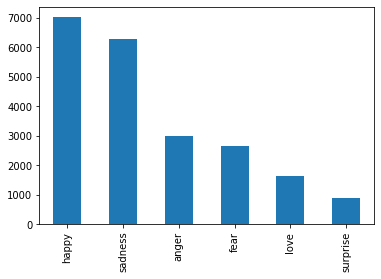

In [ ]:
# Value Counts of Emotions
df['Emotion'].value_counts().plot(kind='bar')

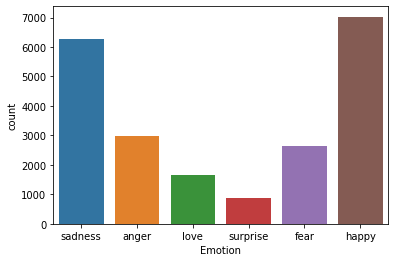

In [ ]:
# Plot
sns.countplot(x='Emotion',data=df)

### Sentiment Analysis

In [ ]:
from textblob import TextBlob

In [ ]:
def get_sentiment(text):
  blob = TextBlob(text)
  sentiment = blob.sentiment.polarity
  if sentiment > 0:
    result = "Positive"
  elif sentiment < 0:
    result = "Negative"
  else:
    result = "Neutral"
  return result

In [ ]:
#Test Function
get_sentiment("I love coding")

'Positive'

In [ ]:
df['Sentiment'] = df['Text'].apply(get_sentiment)

In [ ]:
df.head()

,Text,Emotion,Sentiment
0,i didnt feel humiliated,sadness,Neutral
1,i can go from feeling so hopeless to so damned...,sadness,Neutral
2,im grabbing a minute to post i feel greedy wrong,anger,Negative
3,i am ever feeling nostalgic about the fireplac...,love,Negative
4,i am feeling grouchy,anger,Neutral


In [ ]:
#Compare our Emotion vs Sentiment
df.groupby(['Emotion','Sentiment']).size()

Emotion   Sentiment
anger     Negative     1390
          Neutral       806
          Positive      797
fear      Negative     1153
          Neutral       665
          Positive      834
happy     Negative      781
          Neutral      1035
          Positive     5213
love      Negative      318
          Neutral       234
          Positive     1089
sadness   Negative     2934
          Neutral      1592
          Positive     1739
surprise  Negative      329
          Neutral       152
          Positive      398
dtype: int64

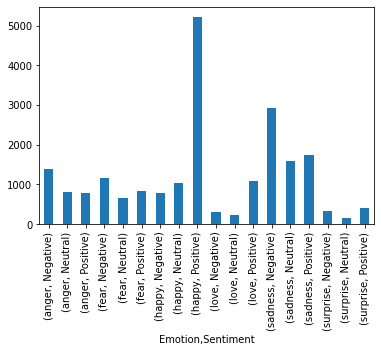

In [ ]:
#First Method :Using Matplotlib
#Compare our Emotion vs Sentiment
df.groupby(['Emotion', 'Sentiment']).size().plot(kind='bar')

In [ ]:
# Using Seaborn
sns.factorplot
sns.catplot

<function seaborn.categorical.catplot>

/usr/local/lib/python3.7/dist-packages/seaborn/categorical.py:3717: UserWarning: The `factorplot` function has been renamed to `catplot`. The original name will be removed in a future release. Please update your code. Note that the default `kind` in `factorplot` (`'point'`) has changed `'strip'` in `catplot`.
  warnings.warn(msg)
/usr/local/lib/python3.7/dist-packages/seaborn/categorical.py:3723: UserWarning: The `size` parameter has been renamed to `height`; please update your code.
  warnings.warn(msg, UserWarning)


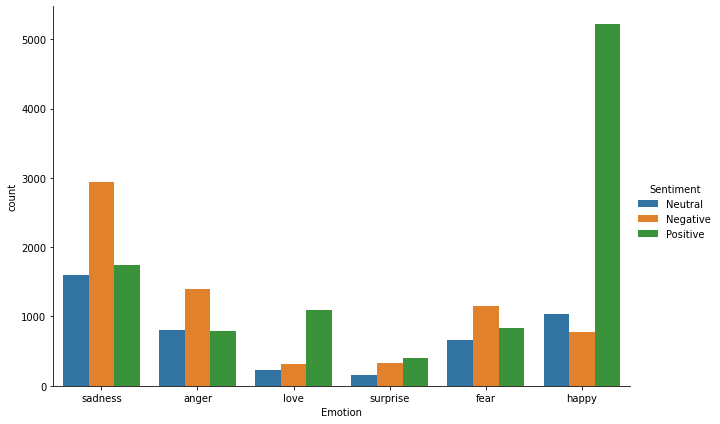

In [ ]:
sns.factorplot(x='Emotion', hue='Sentiment', data=df, kind='count',size=6, aspect=1.5)

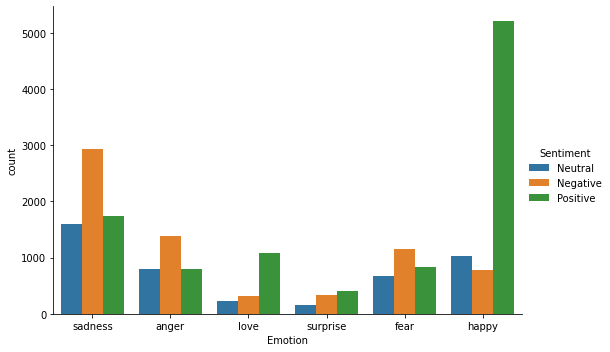

In [ ]:
sns.catplot(x='Emotion',hue='Sentiment',data=df,kind='count',aspect=1.5)

### Text Cleaning
+ Remove noise
  - stopwords
  - special characters
  - punctuations
  - emojis

In [ ]:
dir(nfx)

['BTC_ADDRESS_REGEX',
 'CURRENCY_REGEX',
 'CURRENCY_SYMB_REGEX',
 'Counter',
 'DATE_REGEX',
 'EMAIL_REGEX',
 'EMOJI_REGEX',
 'HASTAG_REGEX',
 'MASTERCard_REGEX',
 'MD5_SHA_REGEX',
 'MOST_COMMON_PUNCT_REGEX',
 'NUMBERS_REGEX',
 'PHONE_REGEX',
 'PoBOX_REGEX',
 'SPECIAL_CHARACTERS_REGEX',
 'STOPWORDS',
 'STOPWORDS_de',
 'STOPWORDS_en',
 'STOPWORDS_es',
 'STOPWORDS_fr',
 'STOPWORDS_ru',
 'STOPWORDS_yo',
 'STREET_ADDRESS_REGEX',
 'TextFrame',
 'URL_PATTERN',
 'USER_HANDLES_REGEX',
 'VISACard_REGEX',
 '__builtins__',
 '__cached__',
 '__doc__',
 '__file__',
 '__generate_text',
 '__loader__',
 '__name__',
 '__numbers_dict',
 '__package__',
 '__spec__',
 '_lex_richness_herdan',
 '_lex_richness_maas_ttr',
 'clean_text',
 'defaultdict',
 'digit2words',
 'extract_btc_address',
 'extract_currencies',
 'extract_currency_symbols',
 'extract_dates',
 'extract_emails',
 'extract_emojis',
 'extract_hashtags',
 'extract_html_tags',
 'extract_mastercard_addr',
 'extract_md5sha',
 'extract_numbers',
 'extr

In [ ]:
# Stopwords
df['Clean_Text'] = df['Text'].apply(nfx.remove_stopwords)

In [ ]:
# User handles
df['Clean_Text'] = df['Clean_Text'].apply(nfx.remove_userhandles)

In [ ]:
# punctuations
df['Clean_Text'] = df['Clean_Text'].apply(nfx.remove_punctuations)

In [ ]:
df[['Text','Clean_Text']]

,Text,Clean_Text
0,i didnt feel humiliated,didnt feel humiliated
1,i can go from feeling so hopeless to so damned...,feeling hopeless damned hopeful cares awake
2,im grabbing a minute to post i feel greedy wrong,im grabbing minute post feel greedy wrong
3,i am ever feeling nostalgic about the fireplac...,feeling nostalgic fireplace know property
4,i am feeling grouchy,feeling grouchy
...,...,...
21454,Melissa stared at her friend in dism,Melissa stared friend dism
21455,Successive state elections have seen the gover...,Successive state elections seen governing part...
21456,Vincent was irritated but not dismay,Vincent irritated dismay
21457,Kendall-Hume turned back to face the dismayed ...,KendallHume turned face dismayed coup


 ### Keyword Extraction
+ Extract most commonest words per class of emotion

In [ ]:
from collections import Counter

In [ ]:
def extract_keywords(text,num=50):
  tokens = [tok for tok in text.split()]
  most_common_tokens = Counter(tokens).most_common(num)
  return dict(most_common_tokens)

In [ ]:
# list of emotions
emotion_list = df['Emotion'].unique().tolist()

In [ ]:
emotion_list

['sadness', 'anger', 'love', 'surprise', 'fear', 'happy']

In [ ]:
happy_list = df[df ['Emotion']=='happy']['Clean_Text'].tolist()
happy_list

['petronas years feel petronas performed huge profit',
 'feel running divine experience expect type spiritual encounter',
 'immense sympathy general point possible proto writer trying find time write corners life sign agent let publishing contract feels little precious',
 'feel reassured anxiety',
 'feeling amused delighted',
 'able help chai lifeline support encouragement great feeling glad able help',
 'feel superior dead chicken grieving child',
 'giddy feeling elegant perfectly fitted pencil skirt',
 'imagine real life scenario emotionally connected feel totally accepted safe morally acceptable close prolonged physical contact sex expected subsequently',
 'sure feel content',
 'feeling need creative',
 'want know causing feel splendid self step away',
 'need need need protected feel safe small find season words',
 'plan share everyday life stories traveling adventures inspirations handmade creations hope feel inspired',
 'christmas trees got feeling festive sure spurring started bo

In [ ]:
# happy document
happy_docx = ' '.join(happy_list)
happy_docx

'petronas years feel petronas performed huge profit feel running divine experience expect type spiritual encounter immense sympathy general point possible proto writer trying find time write corners life sign agent let publishing contract feels little precious feel reassured anxiety feeling amused delighted able help chai lifeline support encouragement great feeling glad able help feel superior dead chicken grieving child giddy feeling elegant perfectly fitted pencil skirt imagine real life scenario emotionally connected feel totally accepted safe morally acceptable close prolonged physical contact sex expected subsequently sure feel content feeling need creative want know causing feel splendid self step away need need need protected feel safe small find season words plan share everyday life stories traveling adventures inspirations handmade creations hope feel inspired christmas trees got feeling festive sure spurring started book ive worn little concealer days im feeling brave dont w

In [ ]:
# Extract Keywords
keyword_happy = extract_keywords(happy_docx)
keyword_happy

{'able': 103,
 'better': 132,
 'bit': 106,
 'come': 102,
 'cool': 94,
 'day': 206,
 'days': 102,
 'dont': 181,
 'excited': 144,
 'feel': 4948,
 'feeling': 1956,
 'feelings': 123,
 'feels': 133,
 'felt': 101,
 'find': 99,
 'free': 102,
 'glad': 97,
 'going': 219,
 'good': 246,
 'got': 127,
 'happy': 212,
 'help': 113,
 'http': 97,
 'im': 1007,
 'important': 105,
 'ive': 216,
 'know': 323,
 'life': 235,
 'like': 1266,
 'little': 239,
 'look': 111,
 'love': 231,
 'makes': 116,
 'need': 168,
 'new': 107,
 'people': 266,
 'person': 93,
 'pretty': 236,
 'right': 153,
 'sure': 144,
 'thankful': 98,
 'things': 180,
 'think': 239,
 'time': 370,
 'today': 153,
 'want': 250,
 'way': 180,
 'wonderful': 94,
 'work': 158,
 'year': 104}

In [ ]:
# Plot
def plot_most_common_words(mydict,emotion_name):
  df_01 = pd.DataFrame(mydict.items(),columns=['token','count'])
  plt.figure(figsize=(20,10))
  plt.title("Plot of {} Most Common Keywords".format(emotion_name))
  sns.barplot(x='token',y='count',data=df_01)
  plt.xticks(rotation=45)
  plt.show()


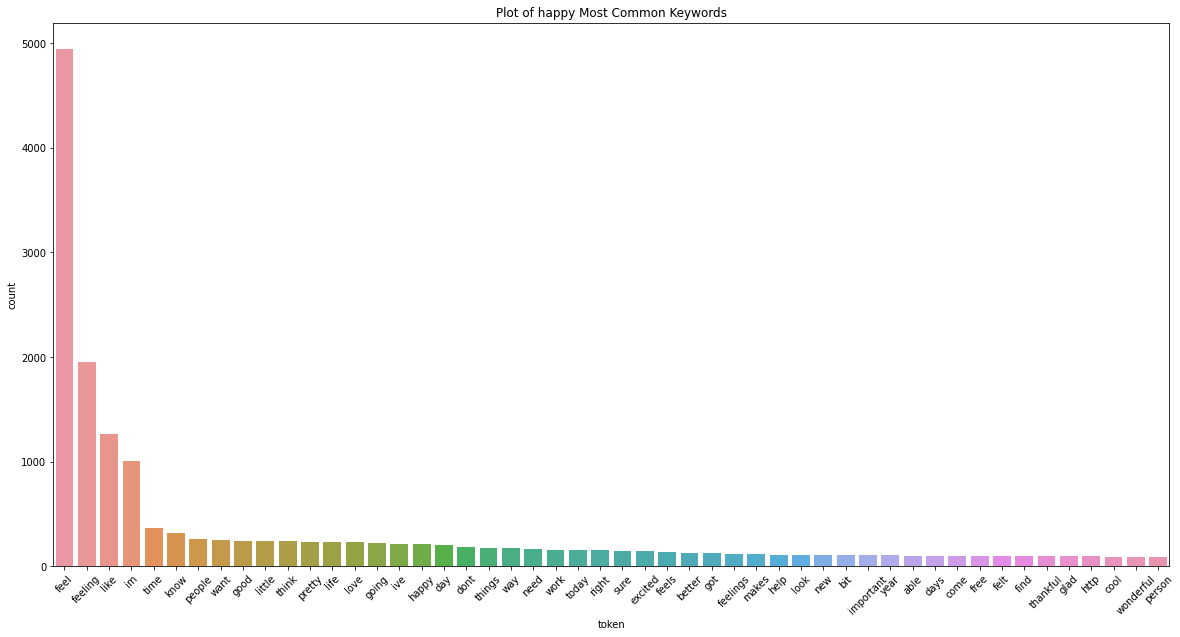

In [ ]:
plot_most_common_words(keyword_happy,"happy")

In [ ]:
surprise_list = df[df ['Emotion']=='surprise']['Clean_Text'].tolist()
# Document
surprise_docx = ' '.join(surprise_list)
# Extract keywords
keyword_surprise = extract_keywords(surprise_docx)

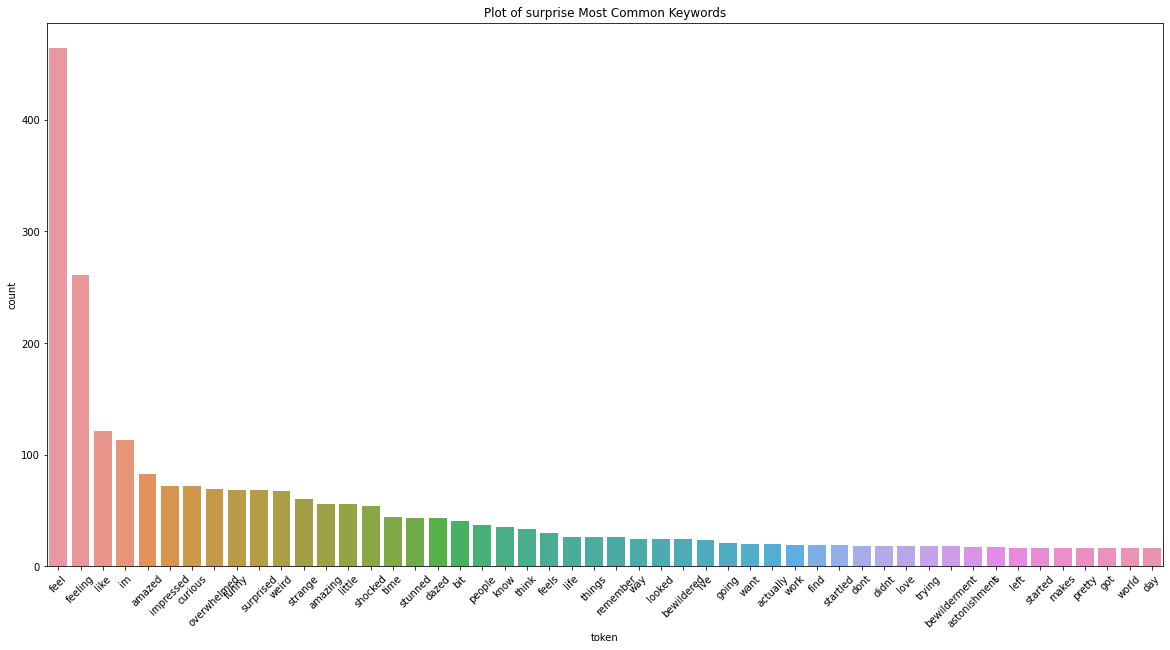

In [ ]:
plot_most_common_words(keyword_surprise,"surprise")

In [ ]:
### Word Cloud
from wordcloud import WordCloud

In [ ]:
def plot_wordcloud(docx):
  mywordcloud = WordCloud().generate(docx)
  plt.figure(figsize=(20,10))
  plt.imshow(mywordcloud,interpolation='bilinear')
  #plt.axis("off")
  plt.show()

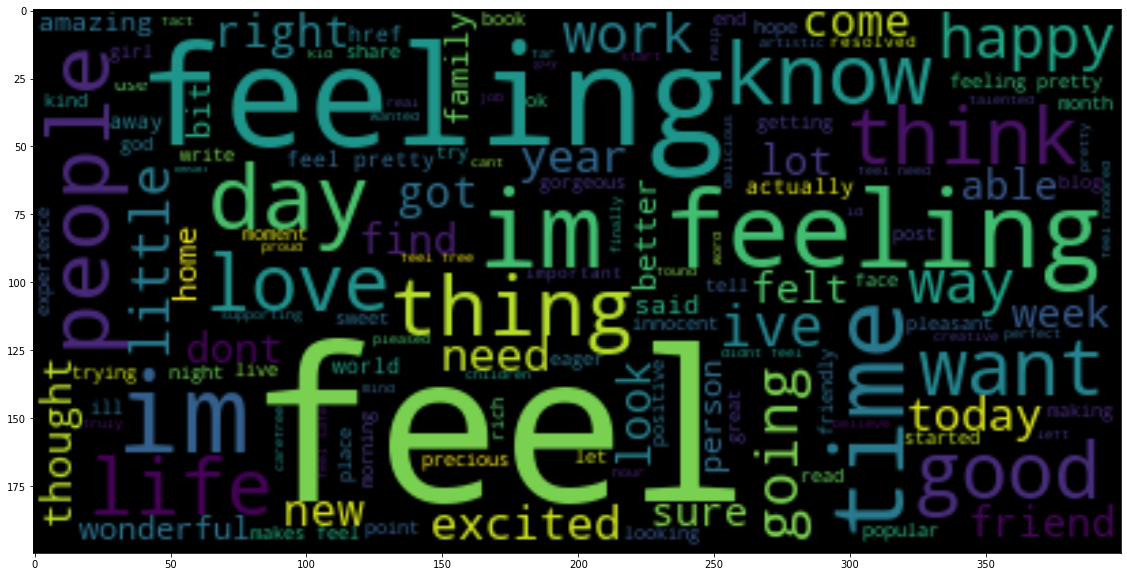

In [ ]:
plot_wordcloud(happy_docx)

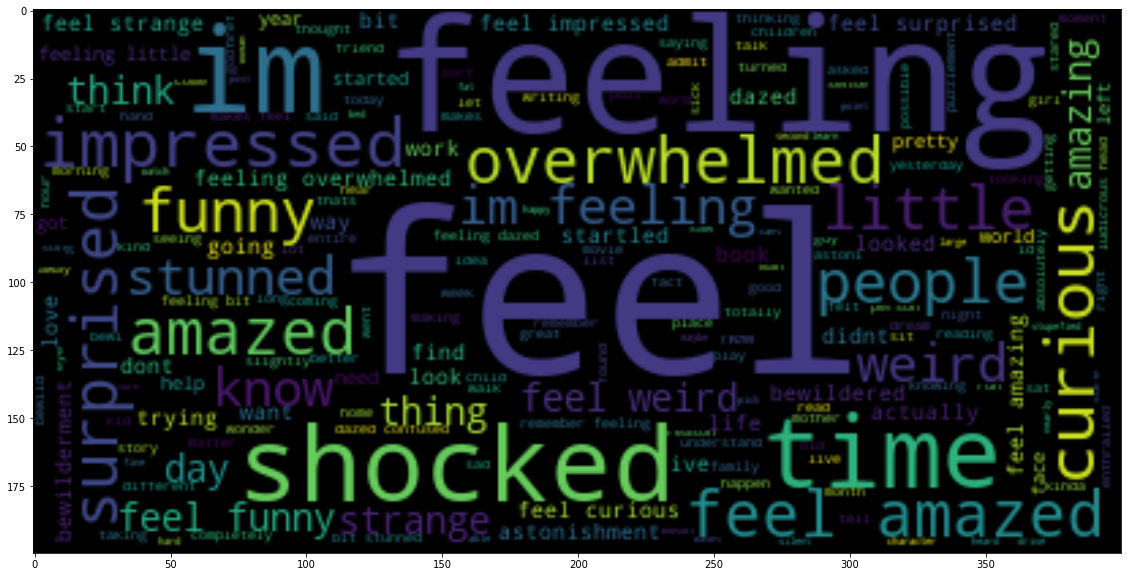

In [ ]:
plot_wordcloud(surprise_docx)

#### Machine Learning
+ Naive Bayes
+ LogisticRegression
+ KNN
+ DecisionTree

#### Compare with SparkNLP / NLU John Snows Lab

### Build Features From our TEXT

In [ ]:
# Features & Labels
Xfeatures = df['Clean_Text']
ylabels = df['Emotion']

In [ ]:
# Vectorizer
cv = CountVectorizer()
X = cv.fit_transform(Xfeatures)

In [ ]:
#  Split Data
X_train,X_test,y_train,y_test = train_test_split(X,ylabels,test_size=0.2,random_state=42)

### **Build Our Model**

### Naive Bayes

In [ ]:
nv_model = MultinomialNB()
nv_model.fit(X_train,y_train)

MultinomialNB()

In [ ]:
# Accuracy
# method 1
nv_model.score(X_test,y_test)

0.7830848089468779

In [ ]:
# Predictions
y_pred_for_nv = nv_model.predict(X_test)

In [ ]:
y_pred_for_nv

array(['happy', 'anger', 'happy', ..., 'anger', 'anger', 'happy'],
      dtype='<U8')

Model Evaluation

In [ ]:
# Classification
print(classification_report(y_test,y_pred_for_nv))

              precision    recall  f1-score   support

       anger       0.89      0.67      0.77       617
        fear       0.83      0.62      0.71       531
       happy       0.76      0.94      0.84      1381
        love       0.80      0.36      0.50       318
     sadness       0.76      0.92      0.83      1277
    surprise       0.76      0.17      0.27       168

    accuracy                           0.78      4292
   macro avg       0.80      0.61      0.65      4292
weighted avg       0.79      0.78      0.76      4292



In [ ]:
# Confusion Matrix
confusion_matrix(y_test,y_pred_for_nv)

array([[ 415,   20,   60,    3,  118,    1],
       [  16,  331,   62,    2,  118,    2],
       [  13,   11, 1292,   17,   45,    3],
       [   3,    6,  156,  115,   38,    0],
       [  16,   10,   63,    5, 1180,    3],
       [   4,   23,   60,    2,   51,   28]])

/usr/local/lib/python3.7/dist-packages/sklearn/utils/deprecation.py:87: FutureWarning: Function plot_confusion_matrix is deprecated; Function `plot_confusion_matrix` is deprecated in 1.0 and will be removed in 1.2. Use one of the class methods: ConfusionMatrixDisplay.from_predictions or ConfusionMatrixDisplay.from_estimator.
  warnings.warn(msg, category=FutureWarning)


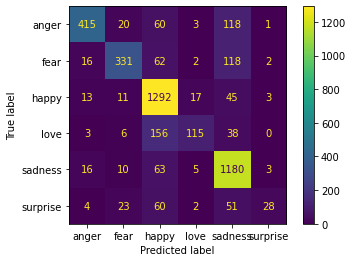

In [ ]:
# Plot Confusion Matrix
plot_confusion_matrix(nv_model,X_test,y_test)

### KNN

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

In [ ]:
knn = KNeighborsClassifier(n_neighbors=10)
knn.fit(X_train, y_train)

knn_predicted = knn.predict(X_test)

In [ ]:
print("Accuracy: ",accuracy_score(y_test,knn_predicted))

Accuracy:  0.5943616029822927


### SVC

In [ ]:
from sklearn.svm import SVC

In [ ]:
svc_model = SVC(C= .2, kernel='linear', gamma= 1)
svc_model.fit(X_train, y_train)

SVC(C=0.2, gamma=1, kernel='linear')

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
pred = svc_model.predict(X_train)
print(classification_report(y_train, pred))
print()
print("Confusion Matrix: \n", confusion_matrix(y_train, pred))
print("Accuracy: \n", accuracy_score(y_train, pred))

              precision    recall  f1-score   support

       anger       0.96      0.94      0.95      2376
        fear       0.92      0.96      0.94      2121
       happy       0.96      0.97      0.96      5648
        love       0.94      0.92      0.93      1323
     sadness       0.97      0.96      0.97      4988
    surprise       0.96      0.86      0.91       711

    accuracy                           0.95     17167
   macro avg       0.95      0.94      0.94     17167
weighted avg       0.95      0.95      0.95     17167


Confusion Matrix: 
 [[2239   29   19   10   77    2]
 [  25 2042   26    5   19    4]
 [  26   35 5490   43   46    8]
 [   1    2  105 1214    0    1]
 [  51   57   68   17 4787    8]
 [   0   62   32    0    4  613]]
Accuracy: 
 0.9544474864565736


/usr/local/lib/python3.7/dist-packages/sklearn/utils/deprecation.py:87: FutureWarning: Function plot_confusion_matrix is deprecated; Function `plot_confusion_matrix` is deprecated in 1.0 and will be removed in 1.2. Use one of the class methods: ConfusionMatrixDisplay.from_predictions or ConfusionMatrixDisplay.from_estimator.
  warnings.warn(msg, category=FutureWarning)


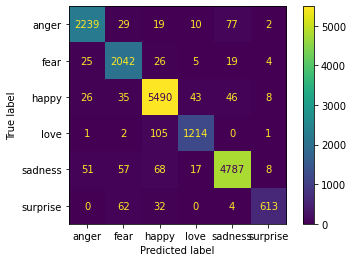

In [ ]:
# Plot Confusion Matrix
plot_confusion_matrix(svc_model,X_train,y_train)

In [ ]:
# Evaluating the model on the testing data set
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
pred = svc_model.predict(X_test)
print(classification_report(y_test, pred))
print()
print("Confusion Matrix: \n", confusion_matrix(y_test, pred))
print("Accuracy: \n", accuracy_score(y_test, pred))

              precision    recall  f1-score   support

       anger       0.91      0.85      0.88       617
        fear       0.81      0.92      0.86       531
       happy       0.90      0.92      0.91      1381
        love       0.80      0.79      0.79       318
     sadness       0.93      0.91      0.92      1277
    surprise       0.84      0.68      0.75       168

    accuracy                           0.89      4292
   macro avg       0.86      0.84      0.85      4292
weighted avg       0.89      0.89      0.89      4292


Confusion Matrix: 
 [[ 527   22   20    6   40    2]
 [  13  487    6    1   15    9]
 [  16   20 1265   40   36    4]
 [   3    3   61  251    0    0]
 [  21   32   43   16 1159    6]
 [   1   36   15    0    2  114]]
Accuracy: 
 0.886067101584343


/usr/local/lib/python3.7/dist-packages/sklearn/utils/deprecation.py:87: FutureWarning: Function plot_confusion_matrix is deprecated; Function `plot_confusion_matrix` is deprecated in 1.0 and will be removed in 1.2. Use one of the class methods: ConfusionMatrixDisplay.from_predictions or ConfusionMatrixDisplay.from_estimator.
  warnings.warn(msg, category=FutureWarning)


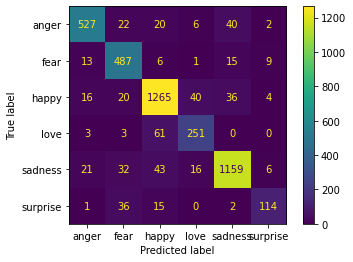

In [ ]:
# Plot Confusion Matrix
plot_confusion_matrix(svc_model,X_test,y_test)

### Radial Basis Mode

In [ ]:
rbf_svc_model = SVC(C= .1, kernel='rbf', gamma= 1)
rbf_svc_model.fit(X_train, y_train)

SVC(C=0.1, gamma=1)

In [ ]:
# Evaluating the model on the training data set
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
pred = rbf_svc_model.predict(X_train)
print(classification_report(y_train, pred))
print()
print("Confusion Matrix: \n", confusion_matrix(y_train, pred))
print("Accuracy: \n", accuracy_score(y_train, pred))

/usr/local/lib/python3.7/dist-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


              precision    recall  f1-score   support

       anger       0.00      0.00      0.00      2376
        fear       0.00      0.00      0.00      2121
       happy       0.33      1.00      0.50      5648
        love       0.00      0.00      0.00      1323
     sadness       0.96      0.01      0.03      4988
    surprise       0.00      0.00      0.00       711

    accuracy                           0.33     17167
   macro avg       0.21      0.17      0.09     17167
weighted avg       0.39      0.33      0.17     17167


Confusion Matrix: 
 [[   0    0 2373    0    3    0]
 [   0    0 2121    0    0    0]
 [   0    0 5648    0    0    0]
 [   0    0 1323    0    0    0]
 [   0    0 4918    0   70    0]
 [   0    0  711    0    0    0]]
Accuracy: 
 0.3330809110502709


/usr/local/lib/python3.7/dist-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.7/dist-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


/usr/local/lib/python3.7/dist-packages/sklearn/utils/deprecation.py:87: FutureWarning: Function plot_confusion_matrix is deprecated; Function `plot_confusion_matrix` is deprecated in 1.0 and will be removed in 1.2. Use one of the class methods: ConfusionMatrixDisplay.from_predictions or ConfusionMatrixDisplay.from_estimator.
  warnings.warn(msg, category=FutureWarning)


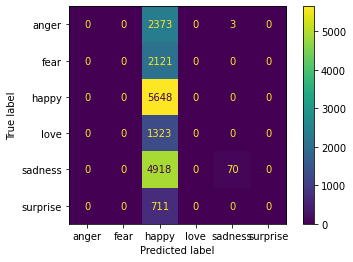

In [ ]:
# Plot Confusion Matrix
plot_confusion_matrix(rbf_svc_model,X_train,y_train)

In [ ]:
# Evaluating the model on the test data set
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
pred = rbf_svc_model.predict(X_test)
print(classification_report(y_test, pred))
print()
print("Confusion Matrix: \n", confusion_matrix(y_test, pred))
print("Accuracy: \n", accuracy_score(y_test, pred))

              precision    recall  f1-score   support

       anger       0.00      0.00      0.00       617
        fear       0.00      0.00      0.00       531
       happy       0.32      1.00      0.49      1381
        love       0.00      0.00      0.00       318
     sadness       0.89      0.01      0.01      1277
    surprise       0.00      0.00      0.00       168

    accuracy                           0.32      4292
   macro avg       0.20      0.17      0.08      4292
weighted avg       0.37      0.32      0.16      4292


Confusion Matrix: 
 [[   0    0  617    0    0    0]
 [   0    0  531    0    0    0]
 [   0    0 1380    0    1    0]
 [   0    0  318    0    0    0]
 [   0    0 1269    0    8    0]
 [   0    0  168    0    0    0]]
Accuracy: 
 0.3233923578751165


/usr/local/lib/python3.7/dist-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.7/dist-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.7/dist-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


/usr/local/lib/python3.7/dist-packages/sklearn/utils/deprecation.py:87: FutureWarning: Function plot_confusion_matrix is deprecated; Function `plot_confusion_matrix` is deprecated in 1.0 and will be removed in 1.2. Use one of the class methods: ConfusionMatrixDisplay.from_predictions or ConfusionMatrixDisplay.from_estimator.
  warnings.warn(msg, category=FutureWarning)


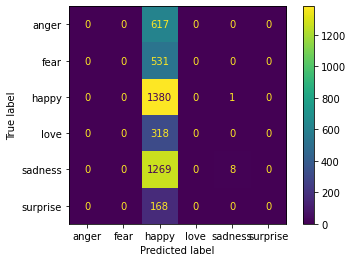

In [ ]:
# Plot Confusion Matrix
plot_confusion_matrix(rbf_svc_model,X_test,y_test)

### Make A Single Prediction
+ Vectorized our Text
+ Applied our model

In [ ]:
sample_text = ["I love coding so much"]

In [ ]:
vect = cv.transform(sample_text).toarray()

In [ ]:
# Make Prediction
#svc_model.predict(vect)

array(['happy'], dtype=object)

In [ ]:
# Make Prediction
nv_model.predict(vect)

array(['happy'], dtype='<U8')

In [ ]:
# Check for the Prediction Probability(Percentage)/Confidence Score
nv_model.predict_proba(vect)

array([[0.08897252, 0.07065389, 0.45057186, 0.12625723, 0.25205627,
        0.01148823]])

In [ ]:
# Get all class for our model
nv_model.classes_

array(['anger', 'fear', 'happy', 'love', 'sadness', 'surprise'],
      dtype='<U8')

In [ ]:
np.max(nv_model.predict_proba(vect))

0.45057186447355496

In [ ]:
def predict_emotion(sample_text,model):
  myvect = cv.transform(sample_text).toarray()
  prediction = model.predict(myvect)
  pred_proba = nv_model.predict_proba(myvect)
  pred_percentage_for_all = dict(zip(model.classes_,pred_proba[0]))
  print("Prediction: {}, Prediction Score: {}".format(prediction[0],np.max(pred_proba)))
  return pred_percentage_for_all

In [ ]:
predict_emotion(sample_text,nv_model)

Prediction: happy, Prediction Score: 0.45057186447355496


{'anger': 0.08897252434666478,
 'fear': 0.07065388886782722,
 'happy': 0.45057186447355496,
 'love': 0.12625722621618451,
 'sadness': 0.25205626810635856,
 'surprise': 0.01148822798941002}

In [ ]:
predict_emotion(["He hates running all day"],nv_model)

Prediction: sadness, Prediction Score: 0.4820478784549542


{'anger': 0.07170110209262064,
 'fear': 0.06757521884019282,
 'happy': 0.3249408506304507,
 'love': 0.04846716054710608,
 'sadness': 0.4820478784549542,
 'surprise': 0.005267789434674735}